# Assignment: Poisson Distribution – Train Arrivals

## Introduction
In this assignment I use the Poisson distribution to model how many trains arrive at a station per hour. The Poisson distribution is used for counting events in a fixed time window when they happen randomly at a steady average rate.

My steps:
- Set up the environment and a random seed
- Create 20 hours of initial train-arrival observations and find the mean
- Plot the distribution with Seaborn
- Calculate the probabilities of more than 9, 10, 11 and 12 trains per hour
- Add 20 hours of observations for the proposed new schedule and recalculate the mean
- Repeat the probability analysis with the updated mean
- Generate 2000 synthetic samples from the updated Poisson process and plot them
- Answer the assignment questions

## 1. Setup the Environment

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import poisson

np.random.seed(42)
sns.set_theme(style="whitegrid")

## 2. Initial Observations

In [2]:
obs = np.array([7, 11, 9, 9, 8, 11, 9, 9, 8, 7, 11, 8, 9, 9, 11, 7, 10, 9, 10, 9])

print("Initial observations:", obs)
print("Number of hours:", len(obs))

Initial observations: [ 7 11  9  9  8 11  9  9  8  7 11  8  9  9 11  7 10  9 10  9]
Number of hours: 20


In [3]:
obs_mean = np.mean(obs)
print(f"Mean trains per hour: {obs_mean:.2f}")

Mean trains per hour: 9.05


## 3. Visualize the Distribution

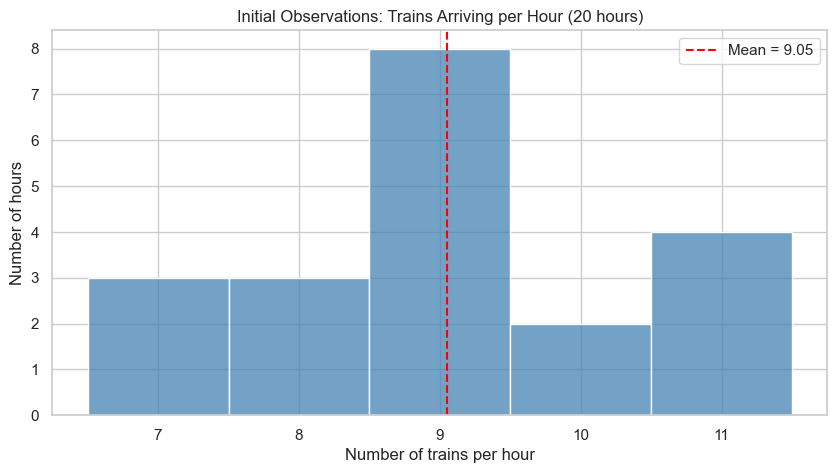

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(obs, discrete=True, color="steelblue")
plt.axvline(obs_mean, color="red", linestyle="--", label=f"Mean = {obs_mean:.2f}")
plt.title("Initial Observations: Trains Arriving per Hour (20 hours)")
plt.xlabel("Number of trains per hour")
plt.ylabel("Number of hours")
plt.legend()
plt.show()

### Interpretation – Initial Observations
- I have 20 hours of data, and each value is the number of trains that arrived in that hour.
- The mean is 9.05 trains per hour. This is λ (lambda), the average rate, and it is the only value the Poisson distribution needs.

### Interpretation – Distribution Plot
- The most common count is 9 trains per hour, which happened in 8 of the 20 hours. The red mean line (9.05) sits right on this peak.
- All hours had between 7 and 11 trains, so there were no extreme or unusual hours.
- The shape is roughly centred around 9, with counts dropping on both sides. It is a bit uneven (11 trains happened 4 times but 10 trains only 2 times) because 20 hours is a small sample.
- The spread is quite narrow. In a true Poisson distribution the variance equals the mean (about 9), but here the counts are much more tightly grouped. This makes sense because trains follow a schedule, so they arrive more regularly than purely random events.

## 4. Calculate Probabilities

In [5]:
k_values = [9, 10, 11, 12]

print(f"Using Poisson with mean (lambda) = {obs_mean:.2f}\n")
for k in k_values:
    prob = poisson.sf(k, obs_mean)
    print(f"P(more than {k} trains) = {prob:.4f}  ({prob * 100:.2f}%)")

Using Poisson with mean (lambda) = 9.05

P(more than 9 trains) = 0.4192  (41.92%)
P(more than 10 trains) = 0.3000  (30.00%)
P(more than 11 trains) = 0.2019  (20.19%)
P(more than 12 trains) = 0.1279  (12.79%)


### Interpretation – Probabilities (Initial Observations)
Using the Poisson distribution with a mean of 9.05 trains per hour:
- P(more than 9 trains) = 41.92%, so in about 4 out of every 10 hours I can expect 10 or more trains.
- P(more than 10 trains) = 30.00%, about 3 out of every 10 hours.
- P(more than 11 trains) = 20.19%, about 1 in 5 hours.
- P(more than 12 trains) = 12.79%, roughly 1 in 8 hours.

The probability drops each time I raise the threshold, because the counts get further away from the average of 9.05.

When I compare this with the real data, the model is a bit high. In the 20 observed hours, only 30% had more than 9 trains, 20% had more than 10, and none had more than 11. This happens because the real arrivals are more tightly grouped than a pure Poisson process. Trains follow a schedule, so very busy hours are rarer than the model expects.

## 5. New Train Schedule – Updated Observations

In [6]:
new_obs = np.array([13, 14, 11, 10, 11, 13, 13, 9, 11, 14, 12, 11, 12, 14, 8, 13, 10, 14, 12, 13])
print("New observations:", new_obs)
print(f"Mean of new observations only: {np.mean(new_obs):.2f}")

New observations: [13 14 11 10 11 13 13  9 11 14 12 11 12 14  8 13 10 14 12 13]
Mean of new observations only: 11.90


In [7]:
all_obs = np.concatenate([obs, new_obs])
print("\nTotal number of hours:", len(all_obs))


Total number of hours: 40


In [8]:
updated_mean = np.mean(all_obs)
print(f"Updated mean trains per hour: {updated_mean:.3f}")

Updated mean trains per hour: 10.475


### Interpretation – New Train Schedule
- The 20 new observations for the proposed schedule have a mean of 11.90 trains per hour, about 2.85 more trains per hour than the original 9.05.
- After joining the old and new data, I have 40 hours in total, and the updated mean is 10.475 trains per hour. This is my new λ (lambda).
- The updated mean is a blend of both schedules, so it sits between 9.05 and 11.90. If the new schedule fully replaces the old one, the real rate would be closer to 11.90.

## 6. Probability Analysis

In [9]:
prob_table = pd.DataFrame({
    "Threshold": [f"More than {k}" for k in k_values],
    "Initial (mean 9.05)": [poisson.sf(k, obs_mean) for k in k_values],
    "Updated (mean 10.475)": [poisson.sf(k, updated_mean) for k in k_values],
})
prob_table["Increase"] = prob_table["Updated (mean 10.475)"] - prob_table["Initial (mean 9.05)"]

print(prob_table.round(4).to_string(index=False))

   Threshold  Initial (mean 9.05)  Updated (mean 10.475)  Increase
 More than 9               0.4192                 0.5999    0.1807
More than 10               0.3000                 0.4762    0.1762
More than 11               0.2019                 0.3583    0.1565
More than 12               0.1279                 0.2555    0.1276


### Interpretation – New Train Schedule
- The 20 new observations for the proposed schedule have a mean of 11.90 trains per hour, about 2.85 more trains per hour than the original 9.05.
- After joining the old and new data, I have 40 hours in total, and the updated mean is 10.475 trains per hour. This is my new λ (lambda).
- The updated mean is a blend of both schedules, so it sits between 9.05 and 11.90. If the new schedule fully replaces the old one, the real rate would be closer to 11.90.

## 7. Generate Synthetic Data

In [10]:
synthetic = np.random.poisson(lam=updated_mean, size=2000)

print("First 20 synthetic values:", synthetic[:20])
print(f"Synthetic mean: {synthetic.mean():.3f}")
print(f"Synthetic variance: {synthetic.var():.3f}")
print(f"Min: {synthetic.min()}, Max: {synthetic.max()}")

First 20 synthetic values: [13  7 11 14  7  8 10 12  8 10  7 11 11  8 12  6  8  8 11  5]
Synthetic mean: 10.383
Synthetic variance: 10.606
Min: 1, Max: 22


## 8. Visualize the Synthetic Data

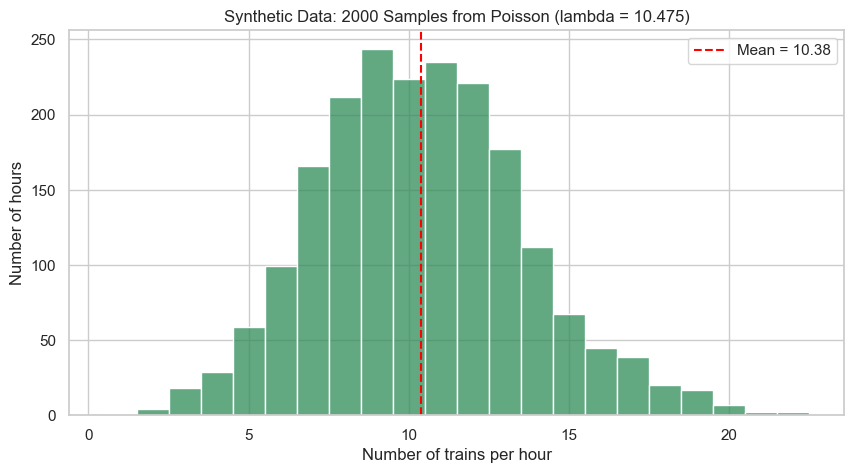

In [11]:
plt.figure(figsize=(10, 5))
sns.histplot(synthetic, discrete=True, color="seagreen")
plt.axvline(synthetic.mean(), color="red", linestyle="--", label=f"Mean = {synthetic.mean():.2f}")
plt.title("Synthetic Data: 2000 Samples from Poisson (lambda = 10.475)")
plt.xlabel("Number of trains per hour")
plt.ylabel("Number of hours")
plt.legend()
plt.show()

### Interpretation – Synthetic Data
- I generated 2000 simulated hours from a Poisson distribution with λ (lambda) = 10.475.
- The synthetic mean is 10.383, very close to 10.475. The small difference is just random sampling noise.
- The synthetic variance is 10.606, almost equal to the mean. This matches the key Poisson property that mean = variance, so the simulation behaves like a true Poisson process.
- The values range from 1 to 22 trains per hour, which is much wider than the real data (7 to 14). With 2000 samples, rare very quiet and very busy hours start to appear.

### Interpretation – Synthetic Data Plot
- The plot has a smooth, single-peaked shape centred around 10 trains per hour, with the red mean line in the middle of the tallest bars.
- It has a slightly longer tail on the right side (up to 22) than on the left (down to 1). This slight right skew is typical for Poisson data, because counts can't go below 0 but can go higher.
- Compared with my 20 real observations, the synthetic data is much smoother because it uses 100 times more samples. It is also more spread out: the real data had a variance of only about 1.65, while the synthetic data's variance is about 10.6. This confirms that the real trains run more regularly than a purely random Poisson process.

## 9. Questions and Answers

### 1. What is the mean of the initial set of observations?
The mean of the initial 20 observations is 9.05 trains per hour.

### 2. How does the distribution of the initial observations look? Describe its shape.
The initial distribution is roughly centred around 9 trains per hour, which is also the most common value (8 of the 20 hours). All values fall between 7 and 11, so the spread is narrow with no extreme hours. The shape is a bit uneven (11 trains appeared 4 times but 10 trains only 2 times) because 20 hours is a small sample. The spread is also much tighter than a true Poisson distribution would have, because scheduled trains arrive more regularly than random events.

### 3. What are the probabilities of observing more than 9, 10, 11, and 12 trains in the initial set?
Using the Poisson distribution with a mean of 9.05:
- More than 9 trains: 0.4192 (41.92%)
- More than 10 trains: 0.3000 (30.00%)
- More than 11 trains: 0.2019 (20.19%)
- More than 12 trains: 0.1279 (12.79%)

## Conclusion
In this assignment I used the Poisson distribution to model train arrivals per hour. The initial mean was 9.05 trains per hour. After adding the expected observations from the proposed schedule, the mean rose to 10.475, and every "more than k trains" probability went up. The chance of more than 12 trains roughly doubled, from 12.79% to 25.55%. The 2000 synthetic samples confirmed the Poisson property that the mean and variance are about equal. Comparing them with the real data also showed that the real trains are more regular than a pure Poisson process, so the model slightly overestimates how often very busy hours happen. For planning, the new schedule means busy hours will become much more common, so the station should prepare for more crowding and staffing needs.

Note: the assignment did not list the observation values, so I used the train-arrival example values from the course textbook (Bonaccorso, *Hands-On Unsupervised Learning with Python*, Chapter 1).